# Análise Exploratória de Dados (EDA) em SQL — LivWell

**Tema:** saúde reprodutiva e planejamento familiar das mulheres

**Grupo:** 
· Antônio Alberto Pereira de Oliveira - 2021086504
· Kauan Valente - 2023060464
· Maria Eduarda Sampaio - 2022055831

**Fonte dos dados:** [Wellbeing of Women in 52 Countries (Kaggle)](https://www.kaggle.com/datasets/konradb/wellbeing-of-women-in-52-countries)

Este notebook adapta o `IBD012-eda.ipynb` (originalmente sobre filmes do IMDb) para os dados do TP. O fluxo pode ser descrito da seguinte forma:

1. **Ingestão** — os CSVs entram no SQLite como tabelas "cruas", com todas as colunas sem tipo;
2. **Entendimento** — dimensões, chaves, dependências funcionais e valores ausentes;
3. **Limpeza** — correções feitas diretamente em SQL;
4. **Análise univariada** — distribuição de cada variável importante;
5. **Normalização** — migração da tabela crua para o esquema relacional do TP (7 relações);
6. **Análise sobre o BD relacional** — perguntas que cruzam várias relações com junções, agregações e funções de janela.

**Para executar:** requer `pandas`, `seaborn` e `matplotlib`. O notebook lê os CSVs em `../data/` e recria do zero o banco `saudefeminina_eda.db`.

## 0. Imports e funções auxiliares

In [1]:
import csv
import sqlite3
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Paleta dos gráficos: cada continente tem a mesma cor e mesmo marcador em todos os gráficos. A paleta sequencial é usada para representar a intensidade de uma variável, enquanto a paleta divergente é usada para mostrar desvios em relação a uma média ou referência.
AZUL, LARANJA, VERDE, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
CINZA, CINZA_CLARO = '#898781', '#f0efec'
CONTINENTES_ORDEM = ['África', 'América', 'Ásia']
COR_CONTINENTE = dict(zip(CONTINENTES_ORDEM, [AZUL, LARANJA, VERDE]))
MARCADOR_CONTINENTE = dict(zip(CONTINENTES_ORDEM, ['o', 's', '^']))
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list('azul', ['#ffffff', '#cde2fb', '#86b6ef', '#2a78d6', '#104281'])
MAPA_DIVERGENTE = LinearSegmentedColormap.from_list('azul_vermelho', [AZUL, CINZA_CLARO, VERMELHO])

plt.rcParams.update({
    'figure.dpi': 110, 'figure.figsize': (9, 4), 'figure.constrained_layout.use': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 2,
})
pd.set_option('display.max_columns', 40, 'display.max_colwidth', 90, 'display.width', 200)

In [2]:
def fetch(query, conn, formatted=True):
    # executa a consulta e busca todas as linhas
    cur = conn.cursor()
    cur.execute(query)
    rs = cur.fetchall()

    # extrai os nomes das colunas a partir da descrição do cursor
    columns = [desc[0] for desc in cur.description]

    # retorna um dataframe com os nomes das colunas
    return pd.DataFrame(rs, columns=columns) if formatted else rs

def show_tables(conn):
    return [x[0] for x in fetch("SELECT tbl_name FROM sqlite_master WHERE type = 'table'", conn, False)]

def shape(table, conn):
    nrows = fetch(f'SELECT COUNT(*) FROM "{table}"', conn, False)[0][0]
    ncols = fetch(f"SELECT COUNT(*) FROM pragma_table_info('{table}')", conn, False)[0][0]

    return (nrows, ncols)

def desc(table, conn):
    cur = conn.cursor()
    cur.execute(f'PRAGMA table_info("{table}")')
    columns = [row[1] for row in cur.fetchall()]

    return columns

def info(table, conn, columns=None):
    # restrições da tabela (domínio, nulo, default, pk)
    df1 = fetch(f'PRAGMA table_info("{table}")', conn)
    columns = columns or desc(table, conn)
    df1 = df1[df1['name'].isin(columns)]

    # linhas por coluna
    counts = ', '.join([f'COUNT(*) AS "{column}"' for column in columns])
    df2 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df2.columns = ['count']

    # valores não nulos por coluna
    counts = ', '.join([f'COUNT("{column}") AS "{column}"' for column in columns])
    df3 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df3.columns = ['notnull count']

    # valores distintos não nulos por coluna
    counts = ', '.join([f'COUNT(DISTINCT "{column}") AS "{column}"' for column in columns])
    df4 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df4.columns = ['unique count']

    return df1.merge(df2, left_on='name', right_index=True) \
            .merge(df3, left_on='name', right_index=True) \
            .merge(df4, left_on='name', right_index=True)

def hist(data, xlabel='', ylabel='Frequência', bins='auto', title='', discrete=False, rotation=90):
    # converte a lista de tuplas em dataframe
    df = pd.DataFrame(data, columns=['key', 'frequency'])
    # expande os dados de acordo com as frequências
    expanded = df.loc[df.index.repeat(df['frequency'])].reset_index(drop=True)

    # plota o histograma
    plt.figure()
    sns.histplot(expanded['key'], bins=bins, discrete=discrete, kde=False,
                 color=AZUL, alpha=1, edgecolor='white', linewidth=1)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=rotation)
    plt.show()

## 1. Ingestão dos dados

Cada CSV vira uma tabela crua (`Source`, `SourceIndicator` e `SourceSelection`), sem nenhum tipo definido nas colunas.

Há um ajuste em relação ao notebook original:

- neste dataset os valores ausentes aparecem como o texto `NA`, e não como campo vazio; por isso os dois casos são convertidos em `NULL`.

In [3]:
# dataset de origem: https://www.kaggle.com/datasets/konradb/wellbeing-of-women-in-52-countries
DATA_DIR = Path('../data')
SOURCES = {
    'Source': DATA_DIR / 'raw' / 'livwell.csv',                           # medições por pesquisa x região
    'SourceIndicator': DATA_DIR / 'raw' / 'indicators.csv',               # dicionário com os 265 indicadores
    'SourceSelection': DATA_DIR / 'processed' / 'filtered_indicators.csv' # 100 indicadores selecionados pelo grupo
}
DB_PATH = Path('saudefeminina_eda.db')

# fecha a conexão de uma execução anterior e recria o banco do zero,
# para que executar o notebook novamente não duplique linhas
if 'conn' in globals():
    conn.close()
DB_PATH.unlink(missing_ok=True)

# conecta ao banco SQLite
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# opções de PRAGMA para acelerar a ingestão
cur.execute('PRAGMA synchronous = OFF')
cur.execute('PRAGMA journal_mode = MEMORY')

# tamanho do lote para processar os dados
BATCH_SIZE = 1000

def ingest(source, table):
    # lê o CSV e insere as linhas em lotes
    with open(source, 'r', encoding='utf-8', newline='') as f:
        reader = csv.reader(f)
        header = next(reader)  # lê a linha de cabeçalho

        # cria a tabela com os nomes das colunas, sem tipos
        columns = [f'"{column}"' for column in header]
        cur.execute(f'CREATE TABLE {table} ({", ".join(columns)})')

        # prepara o INSERT
        placeholders = ', '.join(['?'] * len(header))
        insert = f'INSERT INTO {table} VALUES ({placeholders})'

        # processa as linhas em lotes
        batch = []
        for row in reader:
            batch.append(row)
            if len(batch) == BATCH_SIZE:
                cur.executemany(insert, batch)
                batch = []

        # insere as linhas restantes
        if batch:
            cur.executemany(insert, batch)

    # transforma campos vazios e 'NA' em nulos de verdade
    update = f'UPDATE {table} SET ' + ', '.join(
        [f"{column} = NULLIF(NULLIF({column}, ''), 'NA')" for column in columns])
    cur.execute(update)

for table, source in SOURCES.items():
    ingest(source, table)

# confirma as alterações
conn.commit()

# restaura as opções de PRAGMA
cur.execute('PRAGMA synchronous = FULL')
cur.execute('PRAGMA journal_mode = DELETE')

## 2. Entendimento dos dados

In [4]:
# mostra as tabelas
show_tables(conn)

['Source', 'SourceIndicator', 'SourceSelection']

In [5]:
# dimensões das tabelas
{table: shape(table, conn) for table in show_tables(conn)}

{'Source': (1832, 409),
 'SourceIndicator': (265, 3),
 'SourceSelection': (100, 3)}

In [6]:
# tabela informativa
# apenas colunas de identificação para não poluir a saída
COLUNAS_ID = ['country_name', 'country_code', 'year', 'region_num_harmonized', 'region_name_harmonized',
              'SurveyId', 'interview_year_mean', 'interview_month_mean', 'CMC_interview_mean']

info('Source', conn, COLUNAS_ID)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,country_name,,0,None,0,1832,1832,52
1,1,country_code,,0,None,0,1832,1832,52
2,2,year,,0,None,0,1832,1832,30
3,3,region_num_harmonized,,0,None,0,1832,1832,47
4,4,region_name_harmonized,,0,None,0,1832,1832,447
5,5,SurveyId,,0,None,0,1832,1832,199
6,6,interview_year_mean,,0,None,0,1832,1824,30
7,7,interview_month_mean,,0,None,0,1832,1824,13
8,8,CMC_interview_mean,,0,None,0,1832,1824,1658


In [7]:
# linhas aleatórias
colunas = ', '.join(COLUNAS_ID[:7] + ['FF_TFR', 'RH_contr_modern_p', 'DV_phys_or_sex_partner_12m_p'])
fetch(f'SELECT {colunas} FROM Source ORDER BY random() LIMIT 5', conn)

,country_name,country_code,year,region_num_harmonized,region_name_harmonized,SurveyId,interview_year_mean,FF_TFR,RH_contr_modern_p,DV_phys_or_sex_partner_12m_p
0,Haiti,HTI,2000,2,Sud-Est,HT2000DHS,2000,5.79,9.16,24.82
1,Timor-Leste,TLS,2009,12,Oecussi,TL2009DHS,2009,6.64,15.96,50.04
2,Jordan,JOR,1997,2,Marfraq + Irbid + Aljoun + Jerash,JO1997DHS,1997,4.846,17.82,NaN
3,Senegal,SEN,1997,4,Kolda + Ziguinchor + Sedhiou (South),SN1997DHS,1997,6.507,6.67,NaN
4,Indonesia,IDN,2003,16,North Sulawesi + Gorontalo,ID2003DHS,2002,2.648,46.13,NaN


In [8]:
# mapeamento entre códigos de indicador e nomes de coluna
colunas_source = {coluna.lower(): coluna for coluna in desc('Source', conn)}
selecao = fetch('SELECT indicator_code, indicator_description, indicator_category FROM SourceSelection ORDER BY rowid', conn)

mapa = {}
for codigo in selecao['indicator_code']:
    coluna = codigo.replace('-', '.')
    assert coluna.lower() in colunas_source, f'Coluna não encontrada: {coluna}'
    mapa[codigo] = (coluna, colunas_source.get((coluna + '_se').lower()))

print('Indicadores selecionados:', len(mapa))
print('Indicadores sem erro-padrão:', sum(se is None for _, se in mapa.values()))

Indicadores selecionados: 100
Indicadores sem erro-padrão: 10


### Chave e dependências funcionais

Antes de normalizar, verificamos com SQL o que identifica uma linha e quais atributos determinam outros. Uma dependência `X → Y` só vale se nenhum valor de `X` aparecer associado a mais de um valor de `Y`.

In [9]:
# contagem de linhas e combinações distintas
fetch('''
SELECT COUNT(*) AS linhas,
       COUNT(DISTINCT SurveyId || '|' || country_code || '|' || region_num_harmonized) AS combinacoes_distintas
FROM Source''', conn)

,linhas,combinacoes_distintas
0,1832,1832


In [10]:
def violacoes(lhs, rhs, table='Source'):
    # quantos valores do lado esquerdo estão associados a mais de um valor do lado direito?
    return fetch(f'''
        SELECT COUNT(*) FROM (
            SELECT 1 FROM {table} GROUP BY {lhs} HAVING COUNT(DISTINCT {rhs}) > 1
        )''', conn, False)[0][0]

dependencias = [
    ('country_code', 'country_name'),
    ('country_name', 'country_code'),
    ('SurveyId', 'country_code'),
    ('SurveyId', 'year'),
    ('country_code, region_num_harmonized', 'region_name_harmonized'),
    ('SurveyId', 'interview_year_mean'),
    ('SurveyId', 'CMC_interview_mean'),
]
pd.DataFrame([(l, r, violacoes(l, r)) for l, r in dependencias], columns=['X', 'Y', 'violações de X → Y'])

,X,Y,violações de X → Y
0,country_code,country_name,0
1,country_name,country_code,0
2,SurveyId,country_code,0
3,SurveyId,year,0
4,"country_code, region_num_harmonized",region_name_harmonized,2
5,SurveyId,interview_year_mean,33
6,SurveyId,CMC_interview_mean,197


In [11]:
# quais regiões têm mais de um nome?
fetch('''
SELECT country_code, region_num_harmonized, region_name_harmonized, MIN(year) AS primeira, MAX(year) AS ultima, COUNT(*) AS linhas
FROM Source
WHERE (country_code, region_num_harmonized) IN (
    SELECT country_code, region_num_harmonized
    FROM Source
    GROUP BY country_code, region_num_harmonized
    HAVING COUNT(DISTINCT region_name_harmonized) > 1)
GROUP BY country_code, region_num_harmonized, region_name_harmonized''', conn)

,country_code,region_num_harmonized,region_name_harmonized,primeira,ultima,linhas
0,PER,9,Hauncavelica,1996,1996,1
1,PER,9,Huancavelica,2000,2012,7
2,ZAF,1,Western Cape,1998,1998,1
3,ZAF,1,Western Cape,2016,2016,1


**O que o resultado diz:** a combinação pesquisa × região identifica cada uma das 1.832 linhas e será a base da chave de `Medicao` e de `ColetaPesquisaRegiao`. País e ano dependem apenas da pesquisa. A data da entrevista **não** depende só da pesquisa: o ano médio varia entre regiões em 33 das 199 pesquisas, e a data em CMC (meses contados desde 1900) varia em 197, por isso ela pertence ao relacionamento pesquisa × região. Os nomes de região têm 2 conflitos, que são erros de grafia a corrigir na limpeza.

## 3. Limpeza dos dados

### Nomes de região

In [12]:
# remove espaços sobrando nas pontas e duplicados no meio dos nomes
print('Nomes com espaços sobrando:', fetch('''
    SELECT COUNT(DISTINCT region_name_harmonized) FROM Source
    WHERE region_name_harmonized != TRIM(REPLACE(region_name_harmonized, '  ', ' '))''', conn, False)[0][0])

cur.execute('''UPDATE Source
               SET region_name_harmonized = TRIM(REPLACE(region_name_harmonized, '  ', ' '))''')

# quando a mesma região tem grafias diferentes, adota a grafia da pesquisa mais recente
cur.execute('''UPDATE Source AS t1
               SET region_name_harmonized = (
                 SELECT t2.region_name_harmonized
                 FROM Source AS t2
                 WHERE t2.country_code = t1.country_code
                   AND t2.region_num_harmonized = t1.region_num_harmonized
                 ORDER BY CAST(t2.year AS INT) DESC
                 LIMIT 1)
               WHERE (country_code, region_num_harmonized) IN (
                 SELECT country_code, region_num_harmonized
                 FROM Source
                 GROUP BY country_code, region_num_harmonized
                 HAVING COUNT(DISTINCT region_name_harmonized) > 1)''')

# confirma as alterações
conn.commit()

print('Violações restantes:', violacoes('country_code, region_num_harmonized', 'region_name_harmonized'))

Nomes com espaços sobrando: 10
Violações restantes: 0


### Valores ausentes

O notebook original preenche ausências com a média por gênero e descarta o restante. Essa abordagem não é adequada neste caso, pois não existe nenhuma linha na base sem algum valor ausente para os 100 indicadores selecionados.

In [13]:
# quantidade de valores não nulos de cada indicador
contagens = ', '.join(f'COUNT("{coluna}") AS "{codigo}"' for codigo, (coluna, _) in mapa.items())
presentes = fetch(f'SELECT {contagens} FROM Source', conn).transpose()
presentes.columns = ['presentes']
total_linhas = shape('Source', conn)[0]

cobertura = selecao.set_index('indicator_code').join(presentes)
cobertura['% ausente'] = (100 * (1 - cobertura['presentes'] / total_linhas)).round(1)

# quantidade de linhas sem valores nulos em qualquer um dos indicadores
algum_nulo = ' OR '.join(f'"{coluna}" IS NULL' for coluna, _ in mapa.values())
restantes = fetch(f'SELECT COUNT(*) FROM Source WHERE NOT ({algum_nulo})', conn, False)[0][0]

print(f'Células ausentes: {cobertura["% ausente"].mean():.1f}% em média por indicador')
print(f'Linhas sem nenhum valor ausente nos 100 indicadores: {restantes} de {total_linhas}')
cobertura[['indicator_category', 'presentes', '% ausente']].sort_values('% ausente', ascending=False).head(10)

Células ausentes: 19.3% em média por indicador
Linhas sem nenhum valor ausente nos 100 indicadores: 0 de 1832


,indicator_category,presentes,% ausente
indicator_code,,,
DP_decide_no_contraception_p,Decision power,206,88.8
EI_internet_week_p,Energy and information,211,88.5
EI_internet_day_p,Energy and information,211,88.5
EI_mobile_p,Energy and information,216,88.2
DP_decide_contraception_p,Decision power,222,87.9
RH_family_planning_mobile_p,Reproductive health and fertility,489,73.3
DP_decide_visits_p,Decision power,510,72.2
DP_owns_land_p,Decision power,519,71.7
DP_owns_house_p,Decision power,539,70.6


**Resultado:** nenhuma das 1.832 linhas tem os 100 indicadores completos, de modo que o `dropna` do notebook original apagaria a base inteira.

Por isso, foi decidido não preencher nem descartar as linhas. A ausência dos valores só indica que alguns módulos de indicadores não foram aplicados em certas pesquisas, e preencher com médias inventaria medições, assim como descartar as linhas também não é uma abordagem recomendada neste caso pois isso eliminaria toda a base. Na normalização, cada indicador vira uma linha de `Medicao`, de modo que uma medição não observada simplesmente não gera uma linha.

### Validação de domínio

In [14]:
# percentuais devem estar entre 0 e 100; erros-padrão não podem ser negativos
fora_do_dominio = []
for codigo, (coluna, coluna_se) in mapa.items():
    if codigo.endswith('_p'):
        n = fetch(f'SELECT COUNT(*) FROM Source WHERE CAST("{coluna}" AS REAL) NOT BETWEEN 0 AND 100', conn, False)[0][0]
        if n: fora_do_dominio.append((codigo, 'percentual', n))
    if coluna_se:
        n = fetch(f'SELECT COUNT(*) FROM Source WHERE CAST("{coluna_se}" AS REAL) < 0', conn, False)[0][0]
        if n: fora_do_dominio.append((coluna_se, 'erro-padrão', n))

print('Colunas com valores fora do domínio:', fora_do_dominio or 'nenhuma')

Colunas com valores fora do domínio: nenhuma


## 4. Análise univariada

### Pesquisas por país

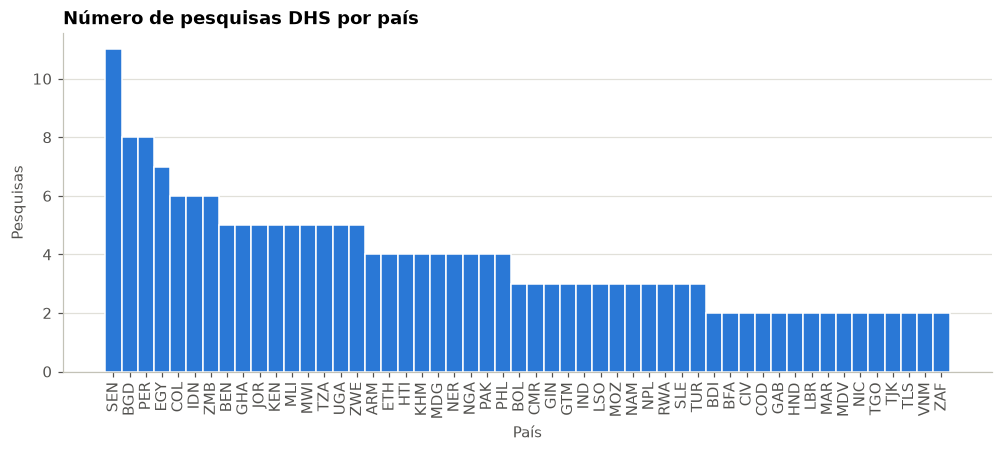

In [15]:
# distribuição de pesquisas por país
distro = fetch('''SELECT country_code, COUNT(DISTINCT SurveyId) AS Frequency
                  FROM Source GROUP BY country_code ORDER BY Frequency DESC, country_code''', conn, False)

# plota o histograma
hist(distro, xlabel='País', ylabel='Pesquisas', title='Número de pesquisas DHS por país', discrete=True)

### Ano da pesquisa

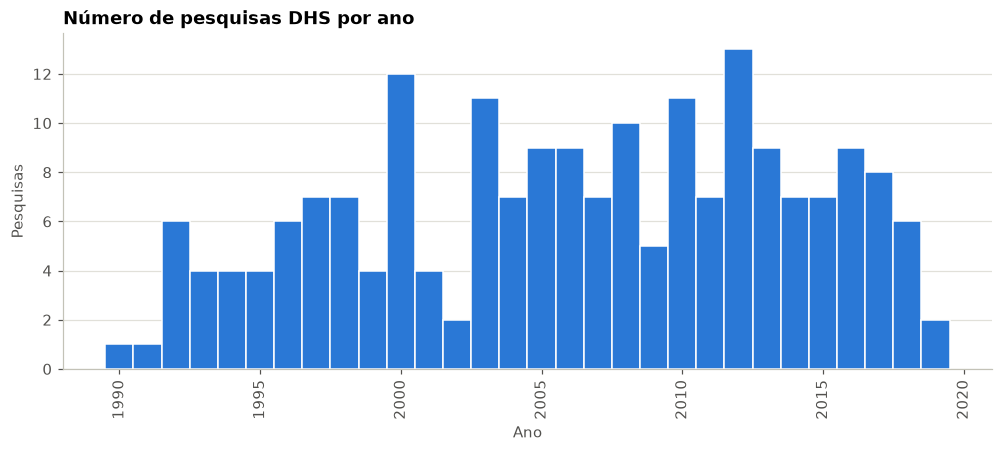

In [16]:
# distribuição de pesquisas por ano
distro = fetch('''SELECT CAST(year AS INT) AS Year, COUNT(DISTINCT SurveyId) AS Frequency
                  FROM Source GROUP BY Year ORDER BY Year''', conn, False)

# plota o histograma
hist(distro, xlabel='Ano', ylabel='Pesquisas', title='Número de pesquisas DHS por ano', discrete=True)

### Regiões por pesquisa

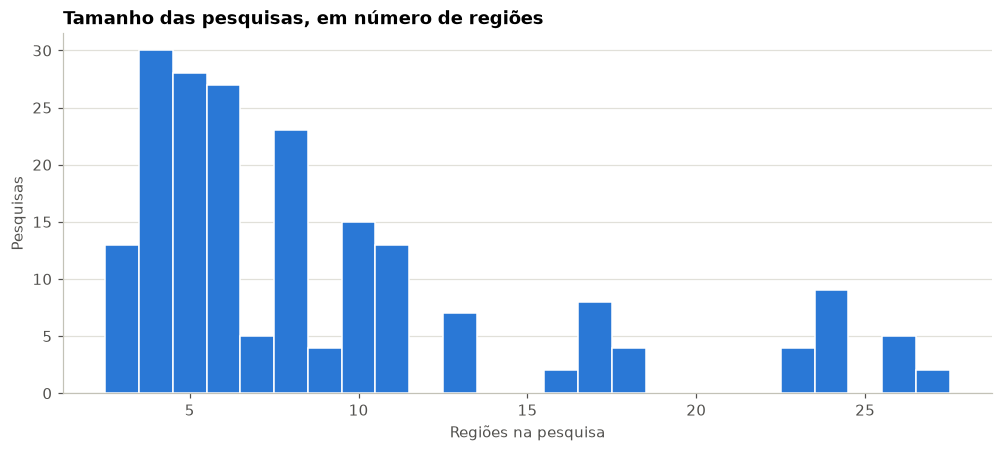

In [17]:
# distribuição de pesquisas pelo número de regiões
distro = fetch('''SELECT Regioes, COUNT(*) AS Frequency
                  FROM (SELECT SurveyId, COUNT(*) AS Regioes FROM Source GROUP BY SurveyId)
                  GROUP BY Regioes ORDER BY Regioes''', conn, False)

# plota o histograma
hist(distro, xlabel='Regiões na pesquisa', ylabel='Pesquisas', title='Tamanho das pesquisas, em número de regiões', discrete=True, rotation=0)

### Cobertura dos indicadores

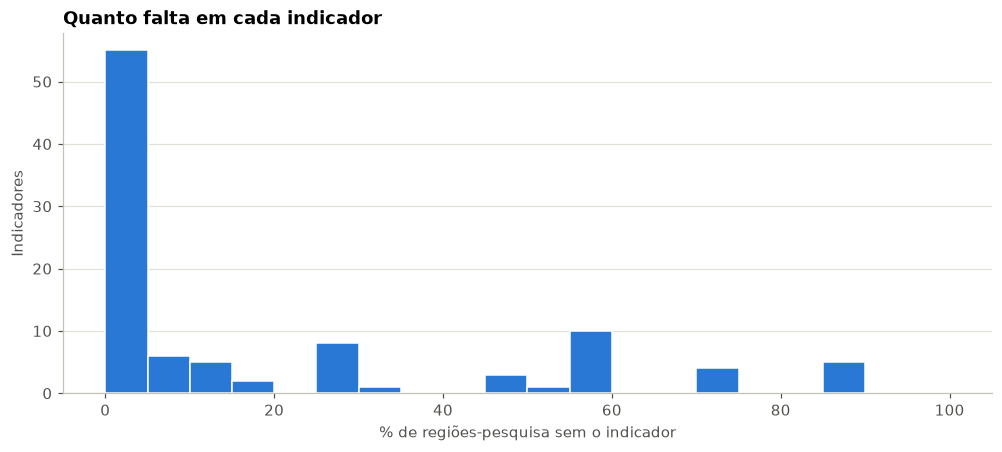

In [18]:
# distribuição do percentual de valores ausentes entre os 100 indicadores
distro = list(cobertura['% ausente'].round().astype(int).value_counts().sort_index().items())

hist(distro, xlabel='% de regiões-pesquisa sem o indicador', ylabel='Indicadores',
     title='Quanto falta em cada indicador', bins=range(0, 101, 5), rotation=0)

O resultado desse histograma indica que a cobertura é muito desigual. 55 dos 100 indicadores têm no máximo 5% de ausência, enquanto 20 têm mais da metade dos valores ausentes. A seção 6.2 mostra que essa ausência se concentra em períodos específicos.

### Indicadores centrais do tema

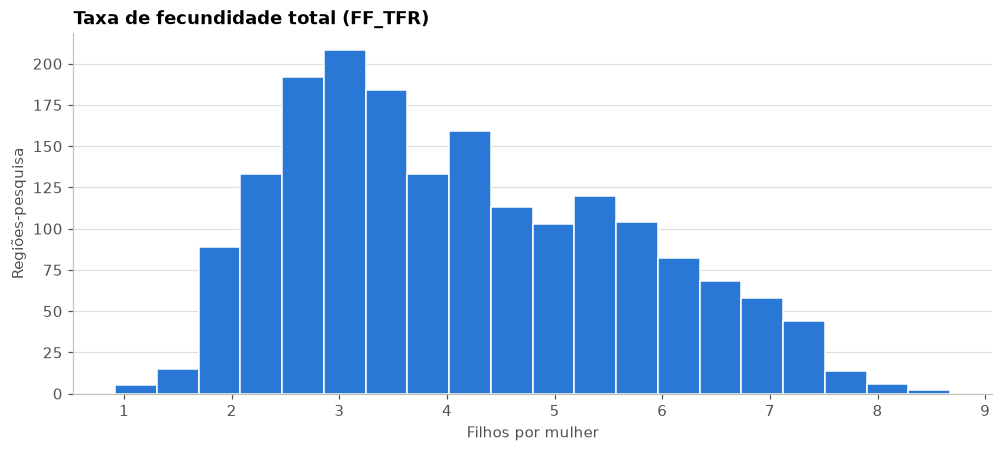

In [19]:
def distribuicao(codigo):
    # distribuição dos valores (não nulos) de um indicador
    coluna = mapa[codigo][0]
    return fetch(f'''SELECT CAST("{coluna}" AS REAL) AS Valor, COUNT(*) AS Frequency
                     FROM Source WHERE "{coluna}" IS NOT NULL GROUP BY Valor ORDER BY Valor''', conn, False)

hist(distribuicao('FF_TFR'), xlabel='Filhos por mulher', ylabel='Regiões-pesquisa',
     title='Taxa de fecundidade total (FF_TFR)', rotation=0)

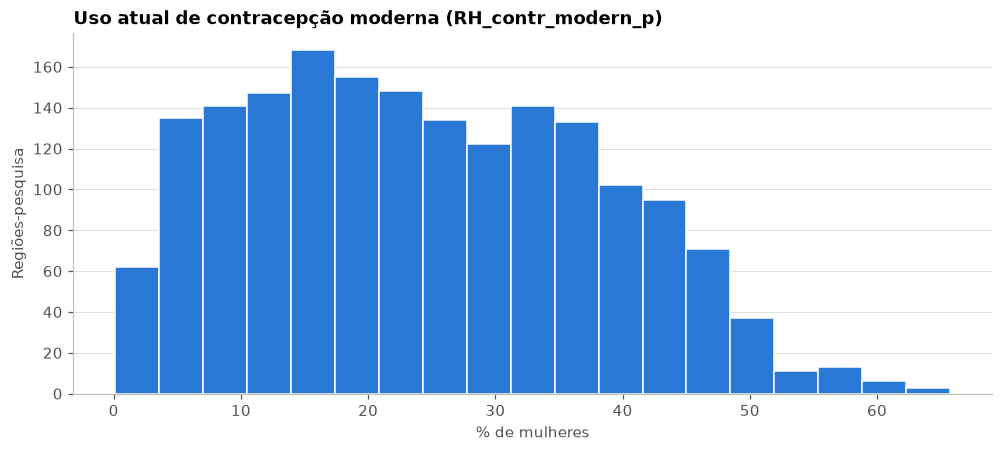

In [20]:
hist(distribuicao('RH_contr_modern_p'), xlabel='% de mulheres', ylabel='Regiões-pesquisa',
     title='Uso atual de contracepção moderna (RH_contr_modern_p)', rotation=0)

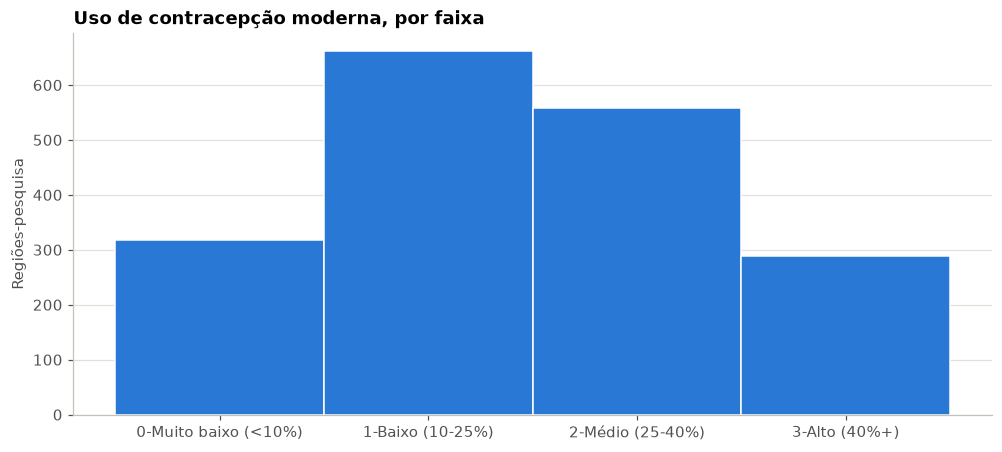

[('0-Muito baixo (<10%)', 317),
 ('1-Baixo (10-25%)', 661),
 ('2-Médio (25-40%)', 558),
 ('3-Alto (40%+)', 288)]

In [21]:
# distribuição discretizada (faixas definidas manualmente)
distro = fetch('''SELECT Faixa, COUNT(*) AS Frequency
                  FROM (SELECT CASE
                          WHEN CAST(RH_contr_modern_p AS REAL) < 10 THEN '0-Muito baixo (<10%)'
                          WHEN CAST(RH_contr_modern_p AS REAL) < 25 THEN '1-Baixo (10-25%)'
                          WHEN CAST(RH_contr_modern_p AS REAL) < 40 THEN '2-Médio (25-40%)'
                          ELSE '3-Alto (40%+)' END AS Faixa
                        FROM Source
                        WHERE RH_contr_modern_p IS NOT NULL)
                  GROUP BY Faixa ORDER BY Faixa''', conn, False)

hist(distro, ylabel='Regiões-pesquisa', title='Uso de contracepção moderna, por faixa', discrete=True, rotation=0)
distro

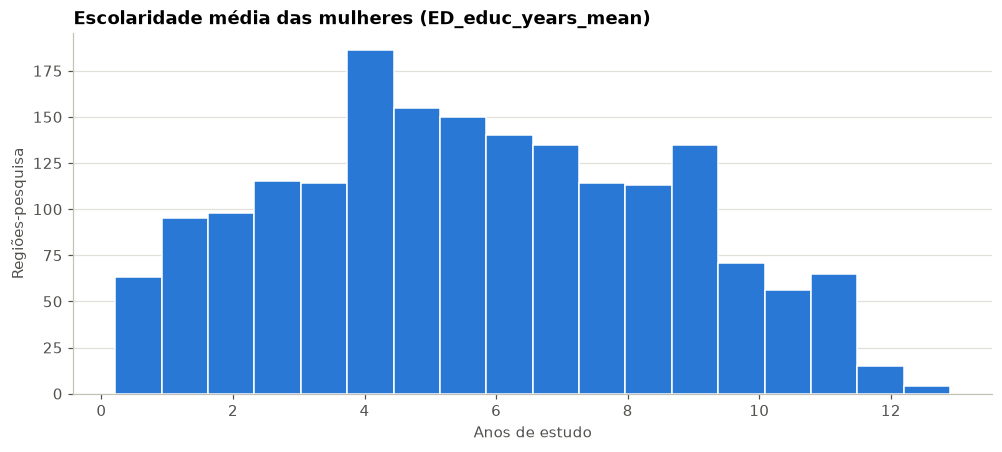

In [22]:
hist(distribuicao('ED_educ_years_mean'), xlabel='Anos de estudo', ylabel='Regiões-pesquisa',
     title='Escolaridade média das mulheres (ED_educ_years_mean)', rotation=0)

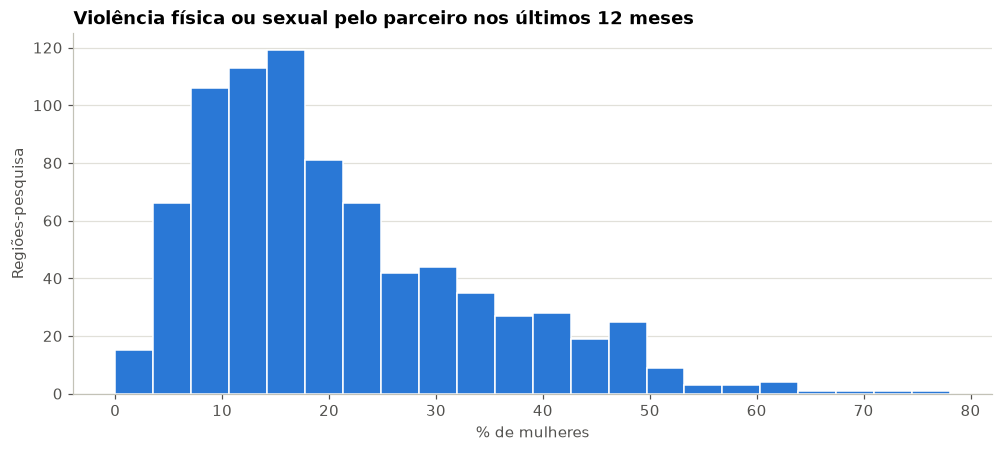

In [23]:
hist(distribuicao('DV_phys_or_sex_partner_12m_p'), xlabel='% de mulheres', ylabel='Regiões-pesquisa',
     title='Violência física ou sexual pelo parceiro nos últimos 12 meses', rotation=0)

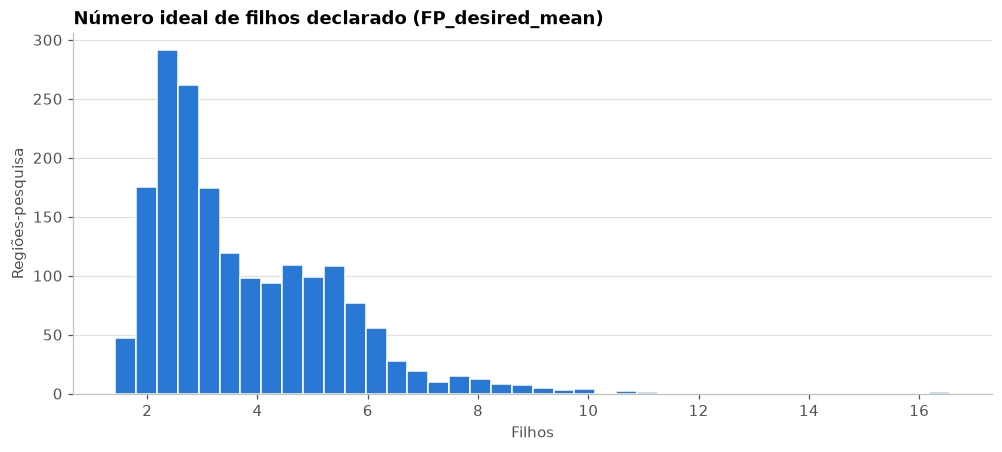

In [24]:
hist(distribuicao('FP_desired_mean'), xlabel='Filhos', ylabel='Regiões-pesquisa',
     title='Número ideal de filhos declarado (FP_desired_mean)', rotation=0)

In [25]:
fetch('''
SELECT country_name, year, region_name_harmonized,
       CAST(FP_desired_mean AS REAL) AS ideal,
       CAST(FP_desired_mean_se AS REAL) AS erro_padrao,
       CAST(FF_TFR AS REAL) AS fecundidade
FROM Source
ORDER BY ideal DESC
LIMIT 8''', conn)

,country_name,year,region_name_harmonized,ideal,erro_padrao,fecundidade
0,Madagascar,1997,Toliara (Anosy + Androy + Atsimo Andrefana + Menabe),16.56,1.27,6.178
1,Kenya,2003,North Eastern,11.15,0.22,6.993
2,Ethiopia,2016,Somali,10.59,0.26,7.207
3,Madagascar,1997,Mahajanga (Sofia + Boeny + Melaky + Betsiboka ),10.51,0.81,6.615
4,Ethiopia,2000,Somali,10.12,0.43,5.066
5,Niger,2012,Maradi,9.97,0.14,8.355
6,Niger,2012,Tillaberi,9.94,0.23,7.854
7,Ethiopia,2005,Somali,9.76,0.63,5.959


A partir dos resultados obtidos, é possível dizer que a maior parte dos valores altos é coerente com regiões de fecundidade muito alta (norte do Quênia, região Somali da Etiópia, Níger). O caso que se destoa é Toliara, em Madagascar (1997), onde obtivemos 16,56 filhos ideais, com erro-padrão de 1,27 e fecundidade de 6,18, o que sugere uma estimativa instável. Como não há evidência de qual seria o valor correto, o dado foi mantido. Para reduzir sua influência, as correlações da seção 6.6 usam o método de Spearman, que compara a posição dos valores no ranking (postos), e não sua magnitude, sendo, portanto, pouco sensível a valores extremos.

## 5. Normalização

### Principais observações

Mesmo esquema relacional da entrega parcial do TP1:

| # | Observação (evidência nas seções anteriores) | Decisão no esquema |
|---|---|---|
| 1 | Nenhuma coluna tem tipo definido | Definir domínios, `NOT NULL`, chaves primárias e estrangeiras |
| 2 | `country_code` ↔ `country_name` | Relação **Pais**, enriquecida com o continente |
| 3 | `(country_code, region_num_harmonized)` → nome, após a limpeza | Relação **Regiao** |
| 4 | `SurveyId` → país e ano | Relação **Pesquisa** |
| 5 | A data da entrevista varia entre regiões da mesma pesquisa | Relacionamento M:N **ColetaPesquisaRegiao** |
| 6 | O texto da categoria se repete em cada indicador | Relação **CategoriaIndicador** |
| 7 | Dicionário de indicadores | Relação **Indicador** |
| 8 | Cada indicador ocupa colunas próprias (grupo repetitivo; muitos nulos) | Relação **Medicao**, com uma linha por pesquisa × região × indicador |


### Migração dos dados

#### Preparar o esquema de destino

In [26]:
# desativar temporariamente a validação de chaves estrangeiras durante a carga
cur.execute('PRAGMA foreign_keys = 0')

# define as restrições de domínio, not null, chave primária e chave estrangeira
ddl = [
    '''
    CREATE TABLE Pais (
        country_code TEXT PRIMARY KEY,
        country_name TEXT NOT NULL,
        continent    TEXT NOT NULL
    );
    ''',
    '''
    CREATE TABLE Regiao (
        country_code           TEXT    NOT NULL REFERENCES Pais(country_code),
        region_num_harmonized  INTEGER NOT NULL,
        region_name_harmonized TEXT    NOT NULL,
        PRIMARY KEY (country_code, region_num_harmonized)
    );
    ''',
    '''
    CREATE TABLE Pesquisa (
        SurveyId           TEXT PRIMARY KEY,
        country_code       TEXT    NOT NULL REFERENCES Pais(country_code),
        year               INTEGER NOT NULL,
        CMC_interview_mean REAL,
        UNIQUE (SurveyId, country_code)
    );
    ''',
    '''
    CREATE TABLE ColetaPesquisaRegiao (
        SurveyId              TEXT    NOT NULL,
        country_code          TEXT    NOT NULL,
        region_num_harmonized INTEGER NOT NULL,
        interview_year_mean   REAL,
        interview_month_mean  REAL,
        CMC_interview_mean    REAL,
        PRIMARY KEY (SurveyId, country_code, region_num_harmonized),
        FOREIGN KEY (SurveyId, country_code)
            REFERENCES Pesquisa(SurveyId, country_code),
        FOREIGN KEY (country_code, region_num_harmonized)
            REFERENCES Regiao(country_code, region_num_harmonized)
    );
    ''',
    '''
    CREATE TABLE CategoriaIndicador (
        category_id      INTEGER PRIMARY KEY,
        category_name    TEXT NOT NULL UNIQUE,
        category_name_pt TEXT NOT NULL,
        category_area    TEXT NOT NULL
    );
    ''',
    '''
    CREATE TABLE Indicador (
        indicator_code        TEXT PRIMARY KEY,
        indicator_description TEXT NOT NULL,
        indicator_type        TEXT NOT NULL,
        category_id           INTEGER NOT NULL REFERENCES CategoriaIndicador(category_id)
    );
    ''',
    '''
    CREATE TABLE Medicao (
        measurement_id        INTEGER PRIMARY KEY,
        SurveyId              TEXT    NOT NULL REFERENCES Pesquisa(SurveyId),
        country_code          TEXT    NOT NULL,
        region_num_harmonized INTEGER NOT NULL,
        indicator_code        TEXT    NOT NULL REFERENCES Indicador(indicator_code),
        value                 REAL    NOT NULL,
        standard_error        REAL,
        FOREIGN KEY (country_code, region_num_harmonized)
            REFERENCES Regiao(country_code, region_num_harmonized),
        UNIQUE (SurveyId, country_code, region_num_harmonized, indicator_code)
    );
    '''
]

for q in ddl:
    cur.execute(q)

# confirma as alterações
conn.commit()

show_tables(conn)

['Source',
 'SourceIndicator',
 'SourceSelection',
 'Pais',
 'Regiao',
 'Pesquisa',
 'ColetaPesquisaRegiao',
 'CategoriaIndicador',
 'Indicador',
 'Medicao']

#### Migrar Pais e Regiao

In [27]:
# o continente não existe no dataset; foi atribuído pelo grupo
# (Turquia e Armênia, transcontinentais, foram classificadas na Ásia)
CONTINENTES = {
    'África': ['BDI', 'BEN', 'BFA', 'CIV', 'CMR', 'COD', 'EGY', 'ETH', 'GAB', 'GHA', 'GIN',
               'KEN', 'LBR', 'LSO', 'MAR', 'MDG', 'MLI', 'MOZ', 'MWI', 'NAM', 'NER', 'NGA',
               'RWA', 'SEN', 'SLE', 'TGO', 'TZA', 'UGA', 'ZAF', 'ZMB', 'ZWE'],
    'América': ['BOL', 'COL', 'GTM', 'HND', 'HTI', 'NIC', 'PER'],
    'Ásia': ['ARM', 'BGD', 'IDN', 'IND', 'JOR', 'KHM', 'MDV', 'NPL', 'PAK', 'PHL', 'TJK',
             'TLS', 'TUR', 'VNM'],
}
caso_continente = 'CASE ' + ' '.join(
    "WHEN country_code IN (" + ', '.join(f"'{p}'" for p in paises) + f") THEN '{continente}'"
    for continente, paises in CONTINENTES.items()) + ' END'

# migra Pais
cur.execute(f'''
INSERT INTO Pais (country_code, country_name, continent)
SELECT DISTINCT country_code, country_name, {caso_continente}
FROM Source
ORDER BY country_code''')

# migra Regiao
cur.execute('''
INSERT INTO Regiao (country_code, region_num_harmonized, region_name_harmonized)
SELECT DISTINCT country_code, CAST(region_num_harmonized AS INTEGER), region_name_harmonized
FROM Source
ORDER BY country_code, CAST(region_num_harmonized AS INTEGER)''')

conn.commit()

info('Pais', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,country_code,TEXT,0,None,1,52,52,52
1,1,country_name,TEXT,1,None,0,52,52,52
2,2,continent,TEXT,1,None,0,52,52,3


In [28]:
info('Regiao', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,country_code,TEXT,1,None,1,481,481,52
1,1,region_num_harmonized,INTEGER,1,None,2,481,481,47
2,2,region_name_harmonized,TEXT,1,None,0,481,481,443


#### Migrar Pesquisa e ColetaPesquisaRegiao

In [29]:
# migra Pesquisa -- CMC_interview_mean é um atributo derivado (média das regiões)
cur.execute('''
INSERT INTO Pesquisa (SurveyId, country_code, year, CMC_interview_mean)
SELECT SurveyId, MIN(country_code), CAST(MIN(year) AS INTEGER), AVG(CAST(CMC_interview_mean AS REAL))
FROM Source
GROUP BY SurveyId''')

# migra ColetaPesquisaRegiao
cur.execute('''
INSERT INTO ColetaPesquisaRegiao
SELECT SurveyId, country_code, CAST(region_num_harmonized AS INTEGER),
       CAST(interview_year_mean AS REAL),
       CAST(interview_month_mean AS REAL),
       CAST(CMC_interview_mean AS REAL)
FROM Source''')

conn.commit()

info('Pesquisa', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,SurveyId,TEXT,0,None,1,199,199,199
1,1,country_code,TEXT,1,None,0,199,199,52
2,2,year,INTEGER,1,None,0,199,199,30
3,3,CMC_interview_mean,REAL,0,None,0,199,197,196


In [30]:
info('ColetaPesquisaRegiao', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,SurveyId,TEXT,1,None,1,1832,1832,199
1,1,country_code,TEXT,1,None,2,1832,1832,52
2,2,region_num_harmonized,INTEGER,1,None,3,1832,1832,47
3,3,interview_year_mean,REAL,0,None,0,1832,1824,30
4,4,interview_month_mean,REAL,0,None,0,1832,1824,13
5,5,CMC_interview_mean,REAL,0,None,0,1832,1824,1658


#### Migrar CategoriaIndicador e Indicador

In [31]:
# nome em português e área temática, definidos pelo grupo
CATEGORIAS = {
    'Decision power': ('Poder de decisão', 'Autonomia e violência'),
    'Domestic Violence': ('Violência doméstica', 'Autonomia e violência'),
    'Education': ('Educação', 'Educação e trabalho'),
    'Work status': ('Situação de trabalho', 'Educação e trabalho'),
    'Energy and information': ('Energia e informação', 'Domicílio e condições de vida'),
    'Energy and information – per urban/rural area': ('Energia e informação – por área urbana/rural', 'Domicílio e condições de vida'),
    'Household characteristics – Womens level': ('Características do domicílio – nível da mulher', 'Domicílio e condições de vida'),
    'Household demographics – Household level': ('Demografia do domicílio – nível do domicílio', 'Domicílio e condições de vida'),
    'Household Wealth': ('Riqueza do domicílio', 'Domicílio e condições de vida'),
    'Socio-economic indicators': ('Indicadores socioeconômicos', 'Domicílio e condições de vida'),
    'Individual demographic information': ('Informações demográficas individuais', 'Demografia'),
    'Fertility – complex indicators': ('Fecundidade – indicadores compostos', 'Saúde reprodutiva'),
    'Fertility preferences': ('Preferências de fecundidade', 'Saúde reprodutiva'),
    'Reproductive health and fertility': ('Saúde reprodutiva e fecundidade', 'Saúde reprodutiva'),
    'Health – Birth level': ('Saúde – nível do nascimento', 'Saúde infantil e nutrição'),
    'Nutrition': ('Nutrição', 'Saúde infantil e nutrição'),
}

# migra CategoriaIndicador
cur.executemany('''INSERT INTO CategoriaIndicador (category_name, category_name_pt, category_area) VALUES (?, ?, ?)''',
                [(nome, pt, area) for nome, (pt, area) in CATEGORIAS.items()])

# migra Indicador -- o tipo é deduzido do sufixo do código
# Percentual: _p; Média: _mean; Taxa: FF_ ou HL_; Valor monetário: gdp_pc; Índice: qualquer outro
cur.execute(r'''
INSERT INTO Indicador (indicator_code, indicator_description, indicator_type, category_id)
SELECT s.indicator_code,
       TRIM(s.indicator_description),
       CASE
           WHEN s.indicator_code LIKE '%\_p' ESCAPE '\' THEN 'Percentual'
           WHEN s.indicator_code LIKE '%\_mean' ESCAPE '\' THEN 'Média'
           WHEN s.indicator_code LIKE 'FF\_%' ESCAPE '\' OR s.indicator_code LIKE 'HL\_%' ESCAPE '\' THEN 'Taxa'
           WHEN s.indicator_code = 'gdp_pc' THEN 'Valor monetário'
           ELSE 'Índice'
       END,
       c.category_id
FROM SourceSelection AS s
JOIN CategoriaIndicador AS c ON s.indicator_category = c.category_name''')

conn.commit()

assert shape('Indicador', conn)[0] == len(mapa), 'Algum indicador ficou sem categoria'

fetch('SELECT indicator_type, COUNT(*) AS indicadores FROM Indicador GROUP BY indicator_type ORDER BY indicadores DESC', conn)

,indicator_type,indicadores
0,Percentual,67
1,Média,15
2,Taxa,14
3,Índice,3
4,Valor monetário,1


#### Migrar Medicao

Cada coluna de indicador vira um conjunto de linhas (saindo do formato de várias colunas para várias linhas), com um `INSERT [...] SELECT` por indicador. Valores ausentes não geram linha, e erros-padrão ausentes ficam nulos.

In [32]:
# migra Medicao
for codigo, (coluna, coluna_se) in mapa.items():
    # a existência de coluna_se é verificada antes de chamar o f-string, para evitar erro de sintaxe no SQL
    erro_padrao = f'CAST("{coluna_se}" AS REAL)' if coluna_se else 'NULL'
    cur.execute(f'''
        INSERT INTO Medicao (SurveyId, country_code, region_num_harmonized, indicator_code, value, standard_error)
        SELECT SurveyId, country_code, CAST(region_num_harmonized AS INTEGER), '{codigo}', CAST("{coluna}" AS REAL), {erro_padrao}
        FROM Source
        WHERE "{coluna}" IS NOT NULL''')

conn.commit()

info('Medicao', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,measurement_id,INTEGER,0,None,1,147829,147829,147829
1,1,SurveyId,TEXT,1,None,0,147829,147829,199
2,2,country_code,TEXT,1,None,0,147829,147829,52
3,3,region_num_harmonized,INTEGER,1,None,0,147829,147829,47
4,4,indicator_code,TEXT,1,None,0,147829,147829,100
5,5,value,REAL,1,None,0,147829,147829,29317
6,6,standard_error,REAL,0,None,0,147829,130176,4082


In [33]:
# verificação: toda célula não nula da Source deve virar exatamente uma linha de Medicao
print('Células não nulas na Source:', int(cobertura['presentes'].sum()))
print('Linhas em Medicao:          ', shape('Medicao', conn)[0])
assert int(cobertura['presentes'].sum()) == shape('Medicao', conn)[0]

Células não nulas na Source: 147829
Linhas em Medicao:           147829


In [34]:
# verificação: a mesma medição, vista na tabela crua e no esquema normalizado
amostra = fetch('''SELECT SurveyId, region_num_harmonized, country_code, FF_TFR, FF_TFR_SE
                   FROM Source WHERE SurveyId = 'NG2018DHS' ORDER BY CAST(region_num_harmonized AS INT) LIMIT 1''', conn)
normalizado = fetch('''
SELECT p.country_name, r.region_name_harmonized, e.year, i.indicator_description, m.value, m.standard_error
FROM Medicao AS m
JOIN Pesquisa AS e ON m.SurveyId = e.SurveyId
JOIN Pais AS p ON e.country_code = p.country_code
JOIN Regiao AS r ON m.country_code = r.country_code AND m.region_num_harmonized = r.region_num_harmonized
JOIN Indicador AS i ON m.indicator_code = i.indicator_code
WHERE m.SurveyId = 'NG2018DHS' AND m.indicator_code = 'FF_TFR'
ORDER BY m.region_num_harmonized
LIMIT 1''', conn)

print(amostra.to_string(index=False), end='\n\n')
print(normalizado.to_string(index=False))

 SurveyId region_num_harmonized country_code FF_TFR FF_TFR_SE
NG2018DHS                     1          NGA  5.029      0.12

country_name region_name_harmonized  year                              indicator_description  value  standard_error
     Nigeria          North Central  2018 Total Fertility Rate (based on a period of 3 year)  5.029            0.12


#### Integridade e limpeza

In [35]:
# reativa a validação e confere a integridade referencial
cur.execute('PRAGMA foreign_keys = 1')
problemas = fetch('PRAGMA foreign_key_check', conn)
print('Violações de chave estrangeira:', len(problemas))
assert problemas.empty

# índice para as análises, que filtram Medicao por indicador
cur.execute('CREATE INDEX idx_medicao_indicador ON Medicao(indicator_code, SurveyId)')

# remove as tabelas cruas e compacta o arquivo
for table in SOURCES:
    cur.execute(f'DROP TABLE {table}')
conn.commit()
cur.execute('VACUUM')

show_tables(conn)

Violações de chave estrangeira: 0


['Pais',
 'Regiao',
 'Pesquisa',
 'ColetaPesquisaRegiao',
 'CategoriaIndicador',
 'Indicador',
 'Medicao']

## 6. Análise exploratória sobre o BD relacional

Com os dados normalizados, as perguntas passam a cruzar país, região, pesquisa, indicador e categoria.

Observações:

- a unidade de análise é a **região em uma pesquisa**, e não a mulher.
- Relações entre regiões não implicam a mesma relação entre indivíduos, pois isso cai na falácia ecológica, e correlação não é causalidade;
- o dataset não traz o tamanho da população, então as médias são simples: uma região pequena pesa o mesmo que uma grande.

### 6.1 Panorama do banco

In [36]:
# medições por área temática e preenchimento
fetch('''
SELECT c.category_area AS area,
       COUNT(DISTINCT i.indicator_code) AS indicadores,
       COUNT(*) AS medicoes,
       ROUND(100.0 * COUNT(*) / (COUNT(DISTINCT i.indicator_code) * (SELECT COUNT(*) FROM ColetaPesquisaRegiao)), 1) AS preenchimento_pct
FROM Medicao AS m
JOIN Indicador AS i ON m.indicator_code = i.indicator_code
JOIN CategoriaIndicador AS c ON i.category_id = c.category_id
GROUP BY c.category_area
ORDER BY medicoes DESC''', conn)

,area,indicadores,medicoes,preenchimento_pct
0,Saúde reprodutiva,23,39621,94.0
1,Domicílio e condições de vida,25,37674,82.3
2,Demografia,13,22460,94.3
3,Educação e trabalho,13,22174,93.1
4,Autonomia e violência,20,15960,43.6
5,Saúde infantil e nutrição,6,9940,90.4


A área com mais medições é a de saúde reprodutiva, com 39.621 registros e 94% de preenchimento, o que sustenta o foco do trabalho nesse tema. Já autonomia e violência é a área menos preenchida (43,6%), porque esses módulos não foram aplicados em todas as pesquisas. Por isso, as análises dessa área trabalham com um conjunto menor de dados.

### 6.2 Uso de métodos contraceptivos entre países

Para comparar os países, usamos a pesquisa mais recente de cada um.

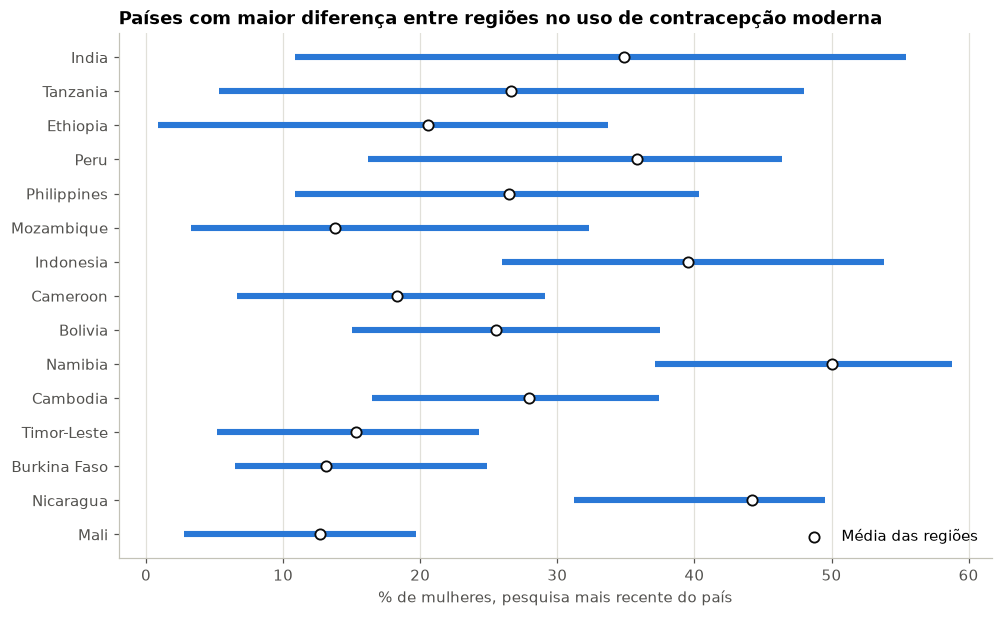

Menor e maior média nacional:
                     pais  ano  media
Congo Democratic Republic 2013    8.3
                 Colombia 2015   61.4



,pais,ano,menor,maior,media,amplitude,regioes
0,India,2006,10.9,55.4,34.9,44.5,26
1,Tanzania,2015,5.3,48.0,26.6,42.7,23
2,Ethiopia,2016,0.9,33.7,20.6,32.8,11
3,Peru,2012,16.2,46.4,35.8,30.2,24
4,Philippines,2017,10.9,40.3,26.5,29.4,17
5,Mozambique,2011,3.3,32.3,13.8,29.1,11
6,Indonesia,2017,26.0,53.8,39.5,27.8,26
7,Cameroon,2018,6.6,29.1,18.3,22.5,6
8,Bolivia,2008,15.0,37.5,25.5,22.5,8
9,Namibia,2013,37.1,58.8,50.0,21.7,13


In [37]:
contracepcao_paises = fetch('''
WITH Ultima AS (
    SELECT SurveyId, country_code, year,
           ROW_NUMBER() OVER (PARTITION BY country_code ORDER BY year DESC) AS ordem
    FROM Pesquisa
)
SELECT p.country_name AS pais, u.year AS ano,
       ROUND(MIN(m.value), 1) AS menor,
       ROUND(MAX(m.value), 1) AS maior,
       ROUND(AVG(m.value), 1) AS media,
       ROUND(MAX(m.value) - MIN(m.value), 1) AS amplitude,
       COUNT(*) AS regioes
FROM Ultima AS u
JOIN Medicao AS m ON m.SurveyId = u.SurveyId
JOIN Pais AS p ON u.country_code = p.country_code
WHERE u.ordem = 1 AND m.indicator_code = 'RH_contr_modern_p'
GROUP BY p.country_name
ORDER BY amplitude DESC''', conn)

top = contracepcao_paises.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hlines(top['pais'], top['menor'], top['maior'], color=AZUL, linewidth=4)
ax.scatter(top['media'], top['pais'], s=45, color='white', edgecolor='#0b0b0b', linewidth=1.2, zorder=3, label='Média das regiões')
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set(title='Países com maior diferença entre regiões no uso de contracepção moderna', xlabel='% de mulheres, pesquisa mais recente do país')
ax.legend(frameon=False, loc='lower right')
plt.show()

print('Menor e maior média nacional:')
print(contracepcao_paises.sort_values('media').iloc[[0, -1]][['pais', 'ano', 'media']].to_string(index=False), end='\n\n')
contracepcao_paises.head(10)

O uso de contracepção moderna varia muito entre os países. A média nacional vai de 8,3% na RD Congo (2013) a 61,4% na Colômbia (2015), uma diferença de cerca de 53 pontos percentuais. Dentro de um mesmo país a distância também pode ser grande: na Índia, o uso vai de 10,9% a 55,4% entre as regiões e, na Tanzânia, de 5,3% a 48,0%. Ou seja, olhar apenas a média nacional esconde realidades bem diferentes.

Vale lembrar que países com mais regiões tendem a apresentar diferenças maiores e que as pesquisas mais recentes não são do mesmo ano. Na Índia, por exemplo, a última pesquisa da base é de 2006.

### 6.3 Fecundidade entre regiões

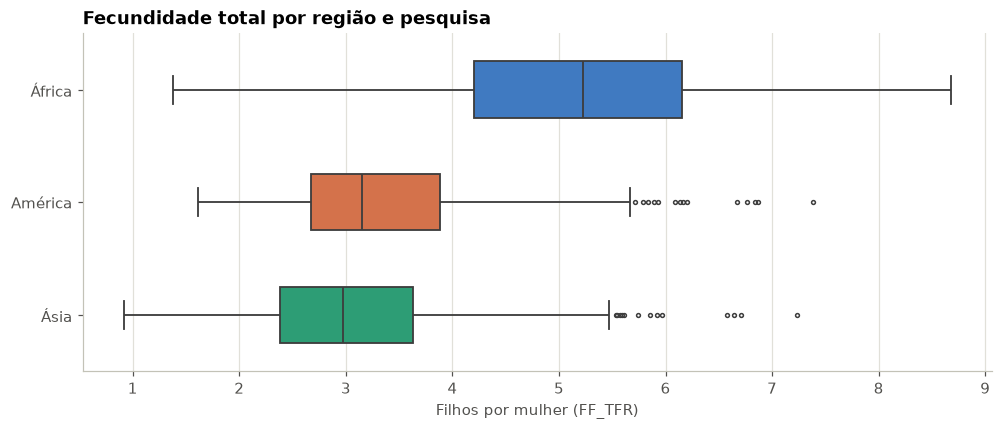

,regioes_pesquisa,paises,mediana
continent,,,
América,374,7,3.2
África,879,31,5.2
Ásia,579,14,3.0


In [38]:
def boxplot_continente(codigo, titulo, xlabel):
    # distribuição de um indicador em cada continente
    dados = fetch(f'''
    SELECT p.continent, p.country_name, m.value
    FROM Medicao AS m
    JOIN Pesquisa AS e ON m.SurveyId = e.SurveyId
    JOIN Pais AS p ON e.country_code = p.country_code
    WHERE m.indicator_code = '{codigo}' ''', conn)

    fig, ax = plt.subplots(figsize=(9, 3.8))
    sns.boxplot(data=dados, y='continent', x='value', order=CONTINENTES_ORDEM, hue='continent', palette=COR_CONTINENTE,
                legend=False, width=0.5, fliersize=2.5, linewidth=1.2, ax=ax)
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    ax.set(title=titulo, xlabel=xlabel, ylabel='')
    plt.show()

    return dados.groupby('continent').agg(regioes_pesquisa=('value', 'size'), paises=('country_name', 'nunique'),
                                          mediana=('value', 'median')).round(1)

boxplot_continente('FF_TFR', 'Fecundidade total por região e pesquisa', 'Filhos por mulher (FF_TFR)')

In [39]:
# regiões com maior e menor fecundidade nas pesquisas desde 2010
def regioes_extremas(ordem):
    return fetch(f'''
    SELECT p.country_name AS pais, r.region_name_harmonized AS regiao, e.year AS ano, ROUND(m.value, 2) AS filhos_por_mulher
    FROM Medicao AS m
    JOIN Pesquisa AS e ON m.SurveyId = e.SurveyId
    JOIN Pais AS p ON e.country_code = p.country_code
    JOIN Regiao AS r ON m.country_code = r.country_code AND m.region_num_harmonized = r.region_num_harmonized
    WHERE m.indicator_code = 'FF_TFR' AND e.year >= 2010
    ORDER BY m.value {ordem}
    LIMIT 5''', conn)

pd.concat({'Maior fecundidade': regioes_extremas('DESC'), 'Menor fecundidade': regioes_extremas('ASC')})

pais            regiao   ano  filhos_por_mulher
Maior fecundidade 0                      Niger            Maradi  2012               8.36
                  1  Congo Democratic Republic  Kasai-Occidental  2013               8.23
                  2                      Niger     Zinder /Diffa  2012               8.21
                  3                   Tanzania    Katavi + Rukwa  2010               8.01
                  4                      Niger         Tillaberi  2012               7.85
Menor fecundidade 0                    Armenia       Gegharkunik  2016               1.05
                  1                    Armenia        Aragatsotn  2016               1.14
                  2                   Ethiopia       Addis Abeba  2011               1.51
                  3                    Armenia              Lori  2016               1.51
                  4                    Armenia           Yerevan  2010               1.53

A fecundidade é bem mais alta na África, onde a mediana é de 5,2 filhos por mulher, contra 3,2 na América e 3,0 na Ásia. Nas pesquisas desde 2010, os valores vão de 1,05 em Gegharkunik, na Armênia, a 8,36 em Maradi, no Níger.

As cinco regiões com maior fecundidade ficam no Níger, na RD Congo e na Tanzânia, enquanto quatro das cinco menores são da Armênia. A quinta é Adis Abeba, capital da Etiópia, um país que também tem região com mais de 7 filhos por mulher.

### 6.4 Relação entre os indicadores

Para medir a relação entre os indicadores, usamos a correlação de Spearman, que compara a posição dos valores no ranking e é pouco sensível a valores extremos.

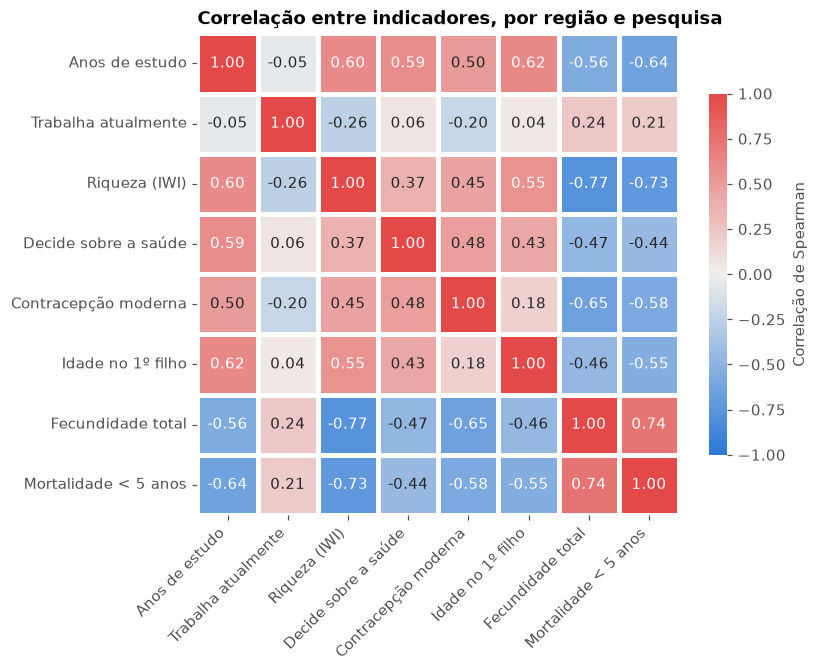

In [40]:
def wide(codigos):
    # volta ao formato de colunas: uma linha por pesquisa x região e uma coluna por indicador
    colunas = ',\n'.join(f"MAX(CASE WHEN m.indicator_code = '{c}' THEN m.value END) AS \"{c}\"" for c in codigos)
    lista = ', '.join(f"'{c}'" for c in codigos)
    return fetch(f'''
    SELECT p.continent, e.year,
           {colunas}
    FROM Medicao AS m
    JOIN Pesquisa AS e ON m.SurveyId = e.SurveyId
    JOIN Pais AS p ON e.country_code = p.country_code
    WHERE m.indicator_code IN ({lista})
    GROUP BY m.SurveyId, m.country_code, m.region_num_harmonized''', conn)

ROTULOS = {
    'ED_educ_years_mean': 'Anos de estudo',
    'WK_working_p': 'Trabalha atualmente',
    'WL_wealth_mean': 'Riqueza (IWI)',
    'DP_decide_health_p': 'Decide sobre a saúde',
    'RH_contr_modern_p': 'Contracepção moderna',
    'RH_age_first_birth_mean': 'Idade no 1º filho',
    'FF_TFR': 'Fecundidade total',
    'HL_U5MR': 'Mortalidade < 5 anos',
}
dados_largos = wide(list(ROTULOS))
corr = dados_largos[list(ROTULOS)].rename(columns=ROTULOS).corr(method='spearman')

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=MAPA_DIVERGENTE, vmin=-1, vmax=1, square=True, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Correlação de Spearman', 'shrink': 0.75}, ax=ax)
ax.set(title='Correlação entre indicadores, por região e pesquisa', xlabel='', ylabel='')
ax.grid(False)
plt.xticks(rotation=45, ha='right')
plt.show()

A fecundidade é menor nas regiões mais ricas (−0,77) e com maior uso de contracepção moderna (−0,65), e maior onde a mortalidade na infância é alta (+0,74). A autonomia das mulheres também aparece ligada à saúde reprodutiva: onde mais mulheres decidem sobre a própria saúde, há mais anos de estudo (+0,59), mais uso de contracepção moderna (+0,48) e menor fecundidade (−0,47). A idade no primeiro filho tende a ser maior nas regiões com mais escolaridade (+0,62) e mais riqueza (+0,55).

O trabalho feminino foge desse padrão. Ele quase não se relaciona com a escolaridade (−0,05) e é um pouco menor nas regiões mais ricas (−0,26). Uma possível explicação é o peso do trabalho agrícola nas regiões mais pobres, hipótese que ainda precisaria ser investigada.

### 6.5 Escolaridade e contracepção moderna

Aqui verificamos se a relação entre escolaridade e contracepção se mantém entre continentes e décadas.

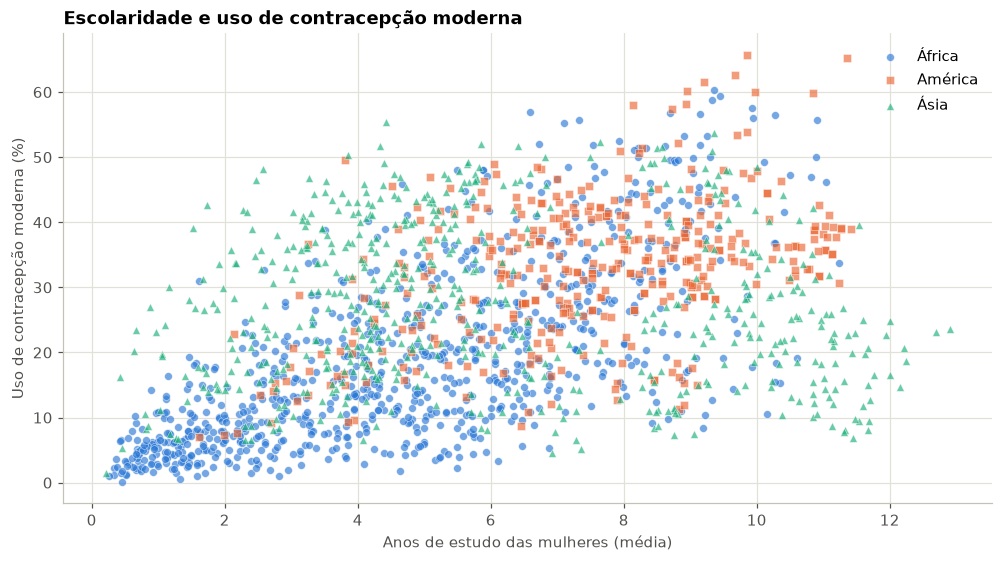

,regioes_pesquisa,spearman
América,374,0.39
África,871,0.72
Ásia,579,-0.02
Década de 1990,408,0.47
Década de 2000,732,0.47
Década de 2010,684,0.50
Todos,1824,0.50


In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
for continente in CONTINENTES_ORDEM:
    d = dados_largos[dados_largos['continent'] == continente]
    ax.scatter(d['ED_educ_years_mean'], d['RH_contr_modern_p'], s=26, alpha=0.65, marker=MARCADOR_CONTINENTE[continente],
               color=COR_CONTINENTE[continente], edgecolor='white', linewidth=0.4, label=continente)
ax.grid(axis='x')
ax.set(title='Escolaridade e uso de contracepção moderna', xlabel='Anos de estudo das mulheres (média)', ylabel='Uso de contracepção moderna (%)')
ax.legend(frameon=False)
plt.show()

def spearman(g):
    # Spearman é a correlação de Pearson aplicada aos postos dos valores
    postos = g[['ED_educ_years_mean', 'RH_contr_modern_p']].dropna().rank()
    return pd.Series({'regioes_pesquisa': len(postos), 'spearman': round(postos['ED_educ_years_mean'].corr(postos['RH_contr_modern_p']), 2)})

grupos = dict(list(dados_largos.groupby('continent')))
grupos |= {f'Década de {d}': g for d, g in dados_largos.groupby(dados_largos['year'] // 10 * 10)}
grupos['Todos'] = dados_largos
pd.DataFrame({nome: spearman(g) for nome, g in grupos.items()}).T.astype({'regioes_pesquisa': int})

No geral, as regiões onde as mulheres estudam mais usam mais contracepção moderna (correlação de 0,50), e esse resultado quase não muda entre as décadas (0,47, 0,47 e 0,50). Entre os continentes, porém, a situação é outra: a relação é forte na África (0,72), moderada na América (0,39) e praticamente inexistente na Ásia (−0,02). Isso mostra que mais escolaridade não vem acompanhada de mais contracepção em todos os contextos com base na nossa base de dados.

### 6.6 Idade no primeiro filho e fatores socioeconômicos

Aqui agrupamos as regiões em faixas de escolaridade e de riqueza e comparamos a idade média das mulheres no primeiro filho. Faixas com menos de 10 regiões-pesquisa ficam de fora.

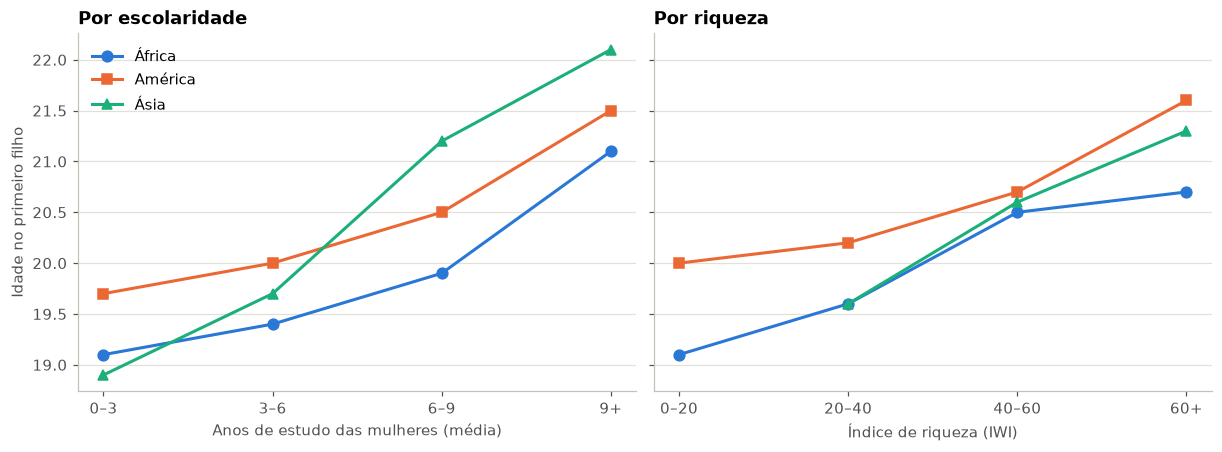

continent               América  África  Ásia
                 faixa                       
Por escolaridade 0–3       19.7    19.1  18.9
                 3–6       20.0    19.4  19.7
                 6–9       20.5    19.9  21.2
                 9+        21.5    21.1  22.1
Por riqueza      0–20      20.0    19.1   NaN
                 20–40     20.2    19.6  19.6
                 40–60     20.7    20.5  20.6
                 60+       21.6    20.7  21.3

In [42]:
def idade_por_faixa(codigo, largura):
    # relaciona a idade no primeiro filho a outro indicador da mesma região e pesquisa, em 4 faixas
    return fetch(f'''
    SELECT p.continent,
           MIN(CAST(x.value / {largura} AS INTEGER), 3) AS faixa,
           ROUND(AVG(i.value), 1) AS idade_media
    FROM Medicao AS i
    JOIN Medicao AS x ON i.SurveyId = x.SurveyId
                     AND i.country_code = x.country_code
                     AND i.region_num_harmonized = x.region_num_harmonized
    JOIN Pais AS p ON i.country_code = p.country_code
    WHERE i.indicator_code = 'RH_age_first_birth_mean' AND x.indicator_code = '{codigo}'
    GROUP BY p.continent, faixa
    HAVING COUNT(*) >= 10
    ORDER BY p.continent, faixa''', conn)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
tabelas = {}
for ax, (codigo, largura, titulo, rotulo) in zip(axes, [
        ('ED_educ_years_mean', 3, 'Por escolaridade', 'Anos de estudo das mulheres (média)'),
        ('WL_wealth_mean', 20, 'Por riqueza', 'Índice de riqueza (IWI)')]):
    dados = idade_por_faixa(codigo, largura)
    for continente in CONTINENTES_ORDEM:
        d = dados[dados['continent'] == continente]
        ax.plot(d['faixa'], d['idade_media'], marker=MARCADOR_CONTINENTE[continente], markersize=7,
                color=COR_CONTINENTE[continente], label=continente)
    faixas = [f'{largura * k}–{largura * (k + 1)}' for k in range(3)] + [f'{3 * largura}+']
    ax.set_xticks(range(4), faixas)
    ax.set(title=titulo, xlabel=rotulo)
    tabelas[titulo] = dados.pivot(index='faixa', columns='continent', values='idade_media').rename(index=dict(enumerate(faixas)))
axes[0].set_ylabel('Idade no primeiro filho')
axes[0].legend(frameon=False)
plt.show()

pd.concat(tabelas)

A idade no primeiro filho aumenta com a escolaridade e com a riqueza nos três continentes. Nas regiões com menos de 3 anos de estudo, as mulheres têm o primeiro filho por volta dos 19 anos (de 18,9 na Ásia a 19,7 na América), enquanto nas regiões com 9 anos ou mais essa idade fica entre 21,1 e 22,1 anos. O maior aumento ocorre na Ásia, de 18,9 para 22,1 anos.

A riqueza segue a mesma direção, com uma variação de 1,6 ano entre a faixa mais pobre e a mais rica na África e na América. Esse resultado é coerente com a seção 6.4, em que a idade no primeiro filho tem correlação de +0,62 com os anos de estudo e de +0,55 com a riqueza.

## 7. Síntese

**Sobre os dados e o banco**

- A base foi transformada em um BD relacional com 7 relações e 147.829 medições, com integridade referencial verificada (nenhuma violação) e total igual ao número de células não nulas da origem.
- A limpeza corrigiu 2 grafias conflitantes e 10 nomes com espaços sobrando; os valores estão dentro do domínio esperado.
- Os valores ausentes não foram preenchidos: são estruturais e estão concentrados em módulos e períodos específicos.

**Sobre o tema**

- A fecundidade está caindo e a contracepção moderna está aumentando na grande maioria dos países, mas a África mantém fecundidade muito acima dos demais continentes.
- A média nacional esconde desigualdades regionais grandes.
- Fecundidade, mortalidade na infância, riqueza e contracepção moderna formam um bloco fortemente associado. Escolaridade e autonomia se associam a esse bloco, e o trabalho feminino não segue o mesmo padrão.

Os resultados precisam ser lidos com alguns cuidados. Os dados são médias por região, então o que vale para uma região pode não valer para cada mulher. Também não temos o tamanho da população, por isso uma região pequena pesa o mesmo que uma grande. Além disso, nem todos os países têm pesquisas em todos os períodos, o que dificulta comparar anos diferentes. Por fim, a maior parte dos dados vem de entrevistas, que podem ter erros de memória ou de relato, e uma correlação entre dois indicadores não significa que um causa o outro.

## Encerramento

In [43]:
# fecha o cursor e a conexão
cur.close()
conn.close()